# 04 · Optimización de hiperparámetros (Workshop S5)

Búsqueda bayesiana con **Optuna** (TPE, semilla fija) sobre la SVM, con validación cruzada estratificada de 5 *folds* **solo sobre los 1.300 textos de entrenamiento y validación**; la prueba no se usa. Después: importancia de hiperparámetros, gráficos de sensibilidad (*slice*), interacción (contorno), *partial dependence* con un modelo sustituto y comparación antes / después con validación cruzada repetida 5×3 e intervalos de confianza.

**Regla:** si la configuración optimizada no supera a la de partida fuera del margen de error, se informa tal cual.

In [1]:
# Preparación del entorno. En Colab, el repositorio vive en Google Drive para que los 5 notebooks compartan
# datos, modelos y resultados entre sesiones.
import os, sys, json, time, platform, shutil
EN_COLAB = "google.colab" in sys.modules
REPO = "github.com/jobedon/triajeia-isp.git"   # repositorio privado
if EN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    DESTINO = "/content/drive/MyDrive/triajeia-isp"
    ZIP = "/content/drive/MyDrive/triajeia-isp.zip"
    try:
        TOKEN = userdata.get("GITHUB_TOKEN")      # Secretos de Colab (🔑): token de solo lectura
    except Exception:
        TOKEN = None
    if TOKEN:
        url = f"https://x-access-token:{TOKEN}@{REPO}"
        if not os.path.exists(f"{DESTINO}/.git"):
            r = os.system(f"git clone -q {url} {DESTINO} > /dev/null 2>&1")
        else:
            # Actualiza SOLO el código: nunca toca results/ ni models/, que generan los propios notebooks.
            r = os.system(f"git -C {DESTINO} fetch -q {url} main > /dev/null 2>&1 && "
                          f"git -C {DESTINO} checkout -q FETCH_HEAD -- src config.yaml data/raw data/guia_etiquetado.md "
                          f"requirements.txt > /dev/null 2>&1")
        print("Código actualizado desde GitHub" if r == 0 else "No se pudo usar GitHub; se usa la copia de Drive")
    elif not os.path.exists(DESTINO) and os.path.exists(ZIP):
        shutil.unpack_archive(ZIP, "/content/drive/MyDrive")
        print("Código extraído de triajeia-isp.zip")
    if not os.path.exists(f"{DESTINO}/config.yaml"):
        raise FileNotFoundError("No se encontró el código. Agregue el secreto GITHUB_TOKEN o suba triajeia-isp.zip a la raíz de Drive.")
    os.chdir(DESTINO)
    os.system('pip install -q "scikit-learn==1.6.1" "optuna>=4" "fairlearn>=0.12"')
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
PRUEBA_RAPIDA = os.environ.get("PRUEBA_RAPIDA", "0") == "1"   # solo para verificar el código; sus números no se usan
print("Directorio:", os.getcwd(), "| Colab:", EN_COLAB, "| Prueba rápida:", PRUEBA_RAPIDA)

Mounted at /content/drive
Código actualizado desde GitHub
Directorio: /content/drive/MyDrive/triajeia-isp | Colab: True | Prueba rápida: False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from src.utils import cargar_config, cargar_json, fijar_semilla, guardar_json

cfg = cargar_config()
SEMILLA = cfg["semilla"]
fijar_semilla(SEMILLA)
FIG, MET = "results/figures", "results/metrics"
os.makedirs(FIG, exist_ok=True); os.makedirs(MET, exist_ok=True); os.makedirs("models", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
GRANATE = "#791632"

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def entorno():
    e = {"colab": EN_COLAB, "prueba_rapida": PRUEBA_RAPIDA, "python": platform.python_version(),
         "sklearn": sklearn.__version__, "pandas": pd.__version__, "fecha": time.strftime("%Y-%m-%d %H:%M")}
    try:
        import torch
        e["torch"] = torch.__version__
        e["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    except ImportError:
        e["gpu"] = None
    return e
NB = "04"

In [3]:
import optuna, warnings
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from src.model import ClasificadorTriaje, construir_svm
optuna.logging.set_verbosity(optuna.logging.WARNING); warnings.filterwarnings("ignore")
P = cfg["datos"]["procesados"]
dev = pd.concat([pd.read_csv(f"{P}/train.csv"), pd.read_csv(f"{P}/val.csv")], ignore_index=True)
OBJ = cfg["datos"]["objetivos"]
N_TRIALS = {"categoria": cfg["optimizacion"]["trials_svm"], "prioridad": cfg["optimizacion"]["trials_svm"] // 2}
if PRUEBA_RAPIDA: N_TRIALS = {o: 6 for o in OBJ}
print(len(dev), N_TRIALS)

1300 {'categoria': 100, 'prioridad': 50}


**Espacio de búsqueda.** `C` en escala logarítmica (en la Semana 3: subajuste con C ≤ 0,01 y sobreajuste con C ≥ 1); n-gramas de palabras hasta 1, 2 o 3; usar o no n-gramas de caracteres y su rango; `min_df`; `sublinear_tf`; `class_weight`. Para que cada *trial* sea rápido se puntúa la SVM sin calibrar: la calibración no cambia la clase predicha más que en casos de empate.

In [4]:
def svm_sin_calibrar(params):
    pipe = construir_svm(params, SEMILLA)
    return Pipeline([("rasgos", pipe.named_steps["rasgos"]), ("clf", pipe.named_steps["clf"].estimator)])

def espacio(trial):
    p = {"C": trial.suggest_float("C", 1e-3, 10, log=True),
         "palabra_ngramas": [1, trial.suggest_int("palabra_ngram_max", 1, 3)],
         "usar_caracteres": trial.suggest_categorical("usar_caracteres", [True, False]),
         "min_df": trial.suggest_int("min_df", 1, 3),
         "sublinear_tf": trial.suggest_categorical("sublinear_tf", [True, False]),
         "class_weight": trial.suggest_categorical("class_weight", ["balanced", None])}
    cmin = trial.suggest_int("caracter_ngram_min", 2, 3)
    p["caracter_ngramas"] = [cmin, trial.suggest_int("caracter_ngram_max", cmin + 1, 6)]
    return p

cv = StratifiedKFold(cfg["optimizacion"]["cv_folds"], shuffle=True, random_state=SEMILLA)
estudios = {}
for o in OBJ:
    def objetivo_optuna(trial, o=o):
        return cross_val_score(svm_sin_calibrar(espacio(trial)), dev["texto"], dev[o], cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    est = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMILLA), study_name=f"svm_{o}")
    est.enqueue_trial({"C": cfg["svm"]["C"], "palabra_ngram_max": 2, "usar_caracteres": True, "min_df": 1,
                       "sublinear_tf": True, "class_weight": "balanced", "caracter_ngram_min": 3, "caracter_ngram_max": 5})
    t0 = time.time(); est.optimize(objetivo_optuna, n_trials=N_TRIALS[o])
    estudios[o] = est
    print(f"{o}: base (trial 0) {est.trials[0].value:.3f} · mejor {est.best_value:.3f} en {time.time() - t0:.0f} s")
    print("   ", est.best_params)

categoria: base (trial 0) 0.985 · mejor 0.986 en 279 s
    {'C': 0.7028540573594115, 'palabra_ngram_max': 3, 'usar_caracteres': True, 'min_df': 1, 'sublinear_tf': True, 'class_weight': 'balanced', 'caracter_ngram_min': 2, 'caracter_ngram_max': 5}
prioridad: base (trial 0) 0.860 · mejor 0.873 en 133 s
    {'C': 7.924996645011359, 'palabra_ngram_max': 3, 'usar_caracteres': True, 'min_df': 1, 'sublinear_tf': False, 'class_weight': 'balanced', 'caracter_ngram_min': 2, 'caracter_ngram_max': 6}


El *trial* 0 es la configuración de partida (encolada a propósito), para que la búsqueda la incluya en igualdad de condiciones.

## 1. Historia e importancia

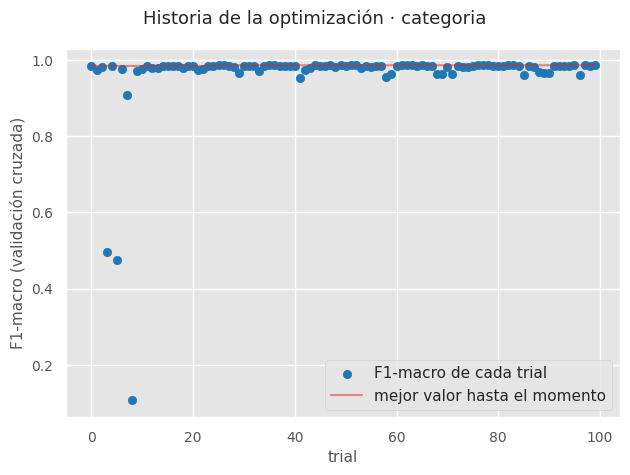

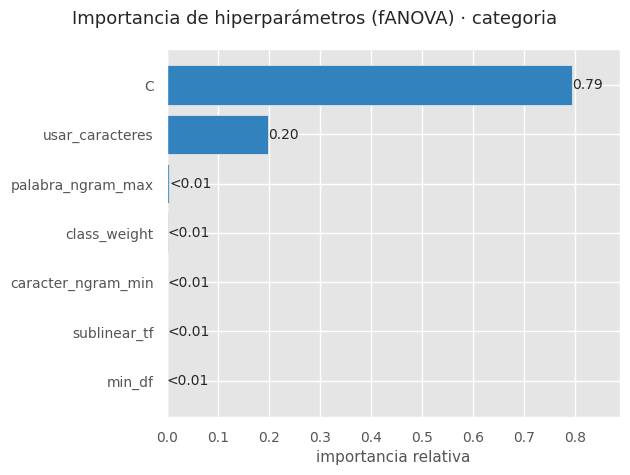

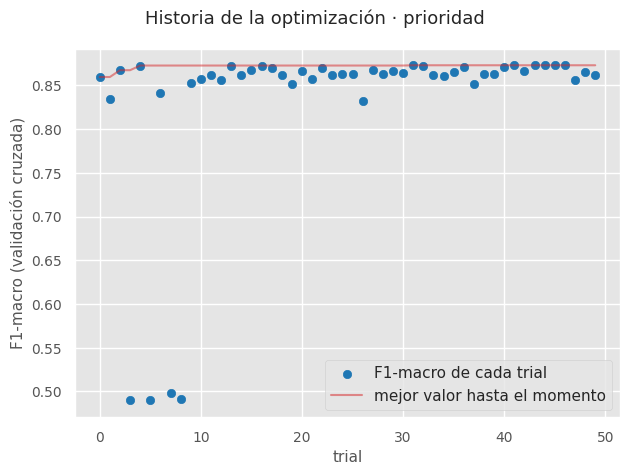

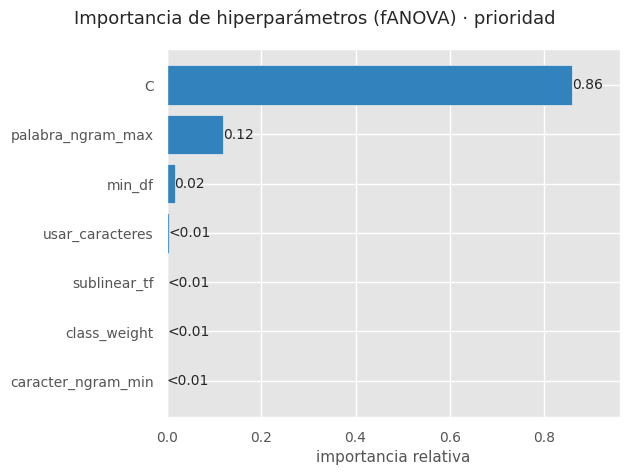

,categoria,prioridad
C,0.794,0.859
usar_caracteres,0.198,0.004
palabra_ngram_max,0.004,0.119
class_weight,0.002,0.001
caracter_ngram_min,0.001,0.000
sublinear_tf,0.000,0.001
min_df,0.000,0.017


In [5]:
from optuna.visualization.matplotlib import plot_contour, plot_optimization_history, plot_param_importances, plot_slice
def estilo_optuna(ax, titulo, xlabel=None, ylabel=None, ancho=None):
    """Reemplaza los títulos en inglés de Optuna por un único título en español."""
    axs = np.atleast_1d(ax).ravel(); fig = axs[0].figure
    for t in fig.texts: t.set_visible(False)
    for a in axs:
        for lugar in ("left", "center", "right"): a.set_title("", loc=lugar)
    fig.suptitle(titulo, fontsize=13); fig._suptitle.set_visible(True)
    if xlabel is not None: axs[0].set_xlabel(xlabel)
    if ylabel is not None: axs[0].set_ylabel(ylabel)
    if ancho: fig.set_size_inches(ancho, 4.5)
    for a in fig.axes:
        a.tick_params(labelsize=10); a.xaxis.label.set_size(11); a.yaxis.label.set_size(11)
    return axs
importancias = {}
for o, est in estudios.items():
    axs = estilo_optuna(plot_optimization_history(est), f"Historia de la optimización · {o}", "trial", "F1-macro (validación cruzada)")
    axs[0].legend(["F1-macro de cada trial", "mejor valor hasta el momento"], loc="lower right"); guardar_fig(f"04_historia_{o}")
    evaluador = optuna.importance.FanovaImportanceEvaluator(seed=SEMILLA)
    importancias[o] = optuna.importance.get_param_importances(est, evaluator=evaluador)
    axs = estilo_optuna(plot_param_importances(est, evaluator=evaluador), f"Importancia de hiperparámetros (fANOVA) · {o}", "importancia relativa", "")
    if axs[0].get_legend() is not None: axs[0].get_legend().remove()
    guardar_fig(f"04_importancia_{o}")
pd.DataFrame(importancias).round(3)

In [6]:
valores = {o: [t.value for t in est.trials if t.value is not None] for o, est in estudios.items()}
for o, v in valores.items():
    print(f"{o}: F1-macro de los trials entre {min(v):.3f} y {max(v):.3f} (rango {max(v) - min(v):.3f}); "
          f"percentil 90: {np.percentile(v, 90):.3f}")

categoria: F1-macro de los trials entre 0.106 y 0.986 (rango 0.880); percentil 90: 0.986
prioridad: F1-macro de los trials entre 0.489 y 0.873 (rango 0.384); percentil 90: 0.873


## 2. Sensibilidad (*slice*) e interacción (contorno)

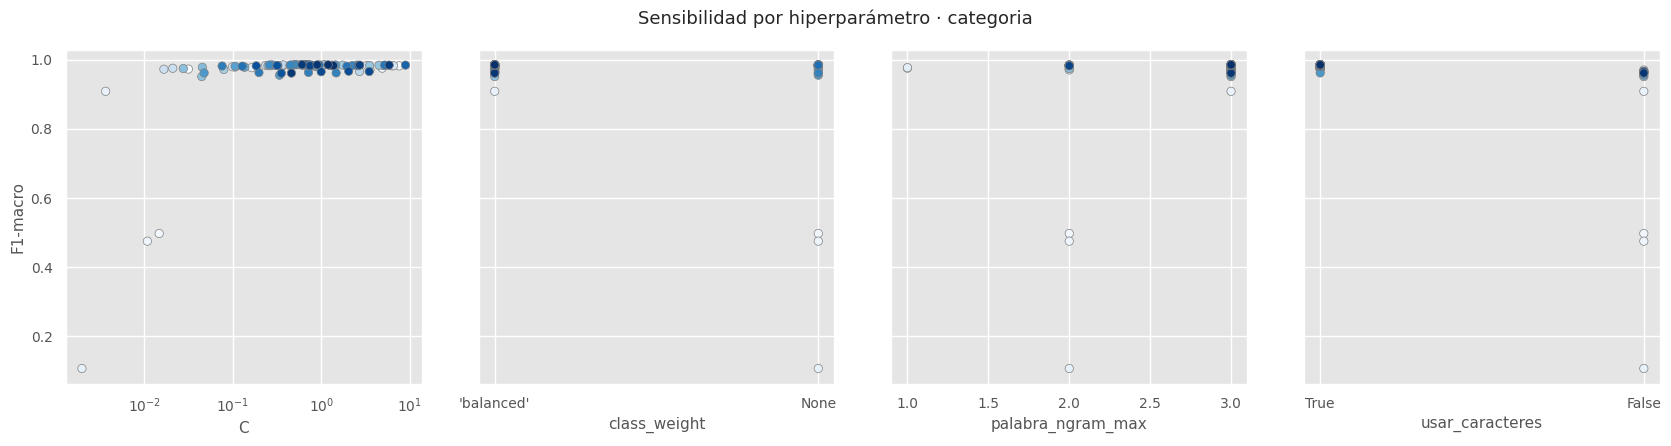

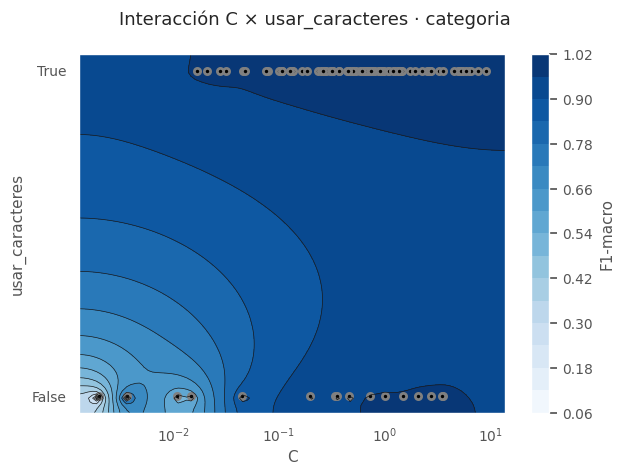

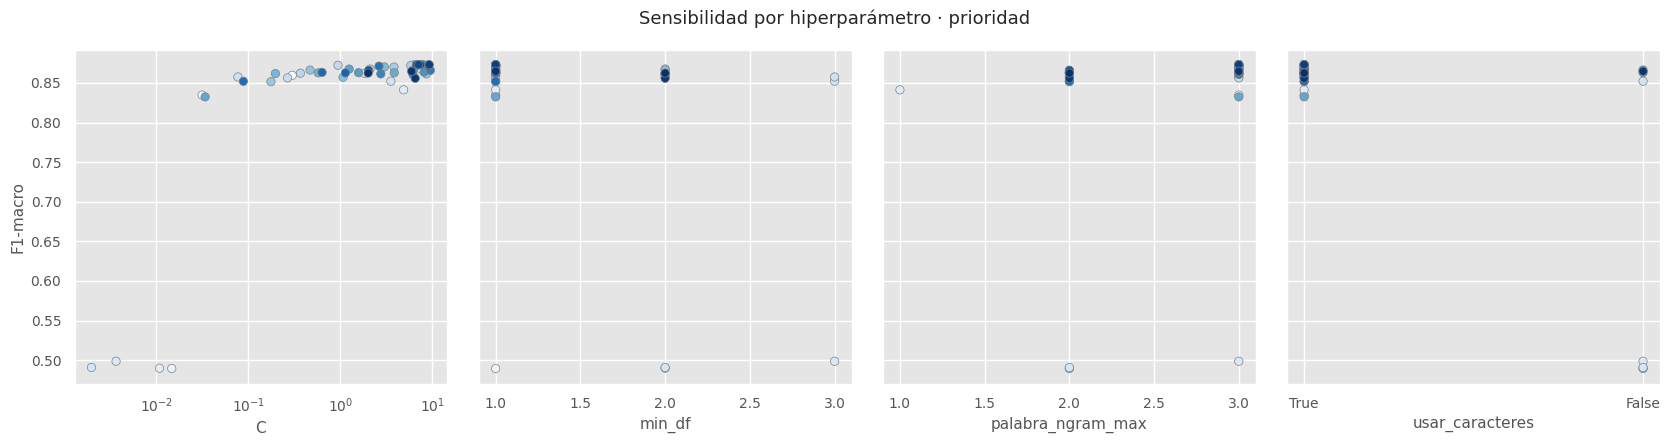

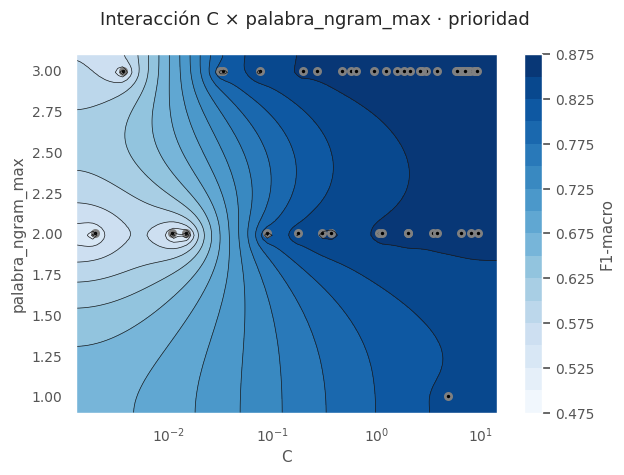

In [7]:
for o, est in estudios.items():
    top = list(importancias[o])[:4]
    axs = estilo_optuna(plot_slice(est, params=top), f"Sensibilidad por hiperparámetro · {o}", ylabel="F1-macro", ancho=4.2 * len(top))
    for a in axs[0].figure.axes[len(top):]: a.remove()   # barra de color del número de trial: se superpone
    guardar_fig(f"04_slice_{o}")
    axs = estilo_optuna(plot_contour(est, params=top[:2]), f"Interacción {top[0]} × {top[1]} · {o}")
    for a in axs[0].figure.axes[1:]: a.set_ylabel("F1-macro")
    guardar_fig(f"04_contorno_{o}")

Lectura: una nube plana indica un hiperparámetro que se puede fijar; una pendiente indica que conviene ajustar su rango; en el contorno, una franja diagonal indica interacción entre los dos hiperparámetros.

## 3. *Partial dependence* con modelo sustituto

Como en el taller, se entrena un `RandomForestRegressor` que predice el F1 de un *trial* a partir de sus hiperparámetros y se grafica la dependencia parcial.

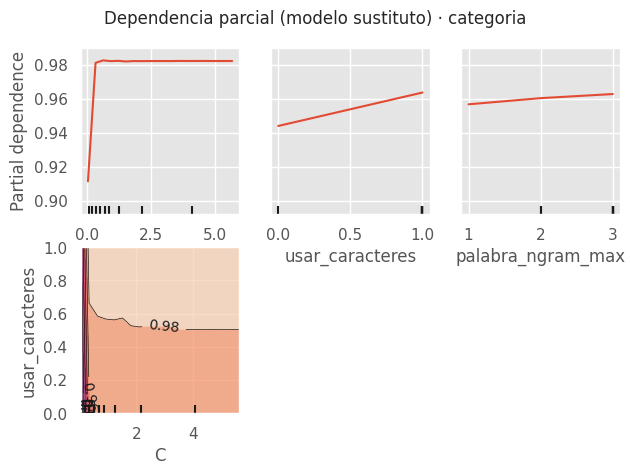

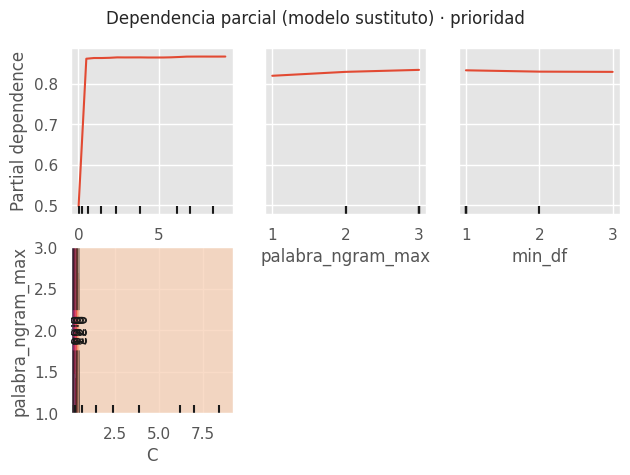

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay
for o, est in estudios.items():
    t = est.trials_dataframe().dropna(subset=["value"])
    X = t[[c for c in t.columns if c.startswith("params_")]].copy()
    for c in X.columns:
        if X[c].dtype == object or X[c].dtype == bool: X[c] = X[c].astype(str).astype("category").cat.codes
    X.columns = [c.replace("params_", "") for c in X.columns]
    sust = RandomForestRegressor(300, random_state=SEMILLA).fit(X, t["value"])
    top = [p for p in importancias[o] if p in X.columns][:3]
    feats = top + ([tuple(top[:2])] if len(top) >= 2 else [])
    PartialDependenceDisplay.from_estimator(sust, X, feats, grid_resolution=20)
    plt.suptitle(f"Dependencia parcial (modelo sustituto) · {o}"); guardar_fig(f"04_pdp_{o}")

## 4. Antes y después

Validación cruzada repetida 5×3 con **los mismos *folds*** para la configuración de partida y la optimizada (modelo calibrado completo). Se reporta media ± desviación estándar, IC 95 % por *bootstrap* de la media y el IC de la diferencia pareada por *fold*. Si el IC de la diferencia incluye el 0, no hay evidencia de mejora.

In [9]:
def a_params(bp):
    p = dict(cfg["svm"])
    p.update({"C": bp["C"], "palabra_ngramas": [1, bp["palabra_ngram_max"]], "usar_caracteres": bp["usar_caracteres"],
              "min_df": bp["min_df"], "sublinear_tf": bp["sublinear_tf"], "class_weight": bp["class_weight"],
              "caracter_ngramas": [bp["caracter_ngram_min"], bp["caracter_ngram_max"]]})
    return p
mejores = {o: a_params(est.best_params) for o, est in estudios.items()}
rcv = RepeatedStratifiedKFold(n_splits=cfg["evaluacion"]["cv_folds"], n_repeats=cfg["evaluacion"]["cv_repeticiones"], random_state=SEMILLA)
if PRUEBA_RAPIDA: rcv = StratifiedKFold(3, shuffle=True, random_state=SEMILLA)
rng = np.random.default_rng(SEMILLA)
def ic_media(x, n=2000):
    b = [np.mean(rng.choice(x, len(x))) for _ in range(n)]; return np.quantile(b, [0.025, 0.975]).tolist()
antes_despues = {}
for o in OBJ:
    a = cross_val_score(construir_svm(cfg["svm"], SEMILLA), dev["texto"], dev[o], cv=rcv, scoring="f1_macro", n_jobs=-1)
    d = cross_val_score(construir_svm(mejores[o], SEMILLA), dev["texto"], dev[o], cv=rcv, scoring="f1_macro", n_jobs=-1)
    dif = d - a
    antes_despues[o] = {"antes": {"media": a.mean(), "de": a.std(), "ic": ic_media(a), "folds": a.tolist()},
                        "despues": {"media": d.mean(), "de": d.std(), "ic": ic_media(d), "folds": d.tolist()},
                        "diferencia": {"media": dif.mean(), "ic": ic_media(dif)}}
    hay_mejora = ic_media(dif)[0] > 0
    print(f"{o}: antes {a.mean():.3f} ± {a.std():.3f} · después {d.mean():.3f} ± {d.std():.3f} · "
          f"diferencia {dif.mean():+.3f} IC95 [{ic_media(dif)[0]:+.3f}; {ic_media(dif)[1]:+.3f}] → "
          f"{'mejora con evidencia' if hay_mejora else 'sin evidencia de mejora'}")
    antes_despues[o]["hay_mejora"] = bool(hay_mejora)

categoria: antes 0.987 ± 0.007 · después 0.988 ± 0.006 · diferencia +0.000 IC95 [-0.002; +0.002] → sin evidencia de mejora
prioridad: antes 0.864 ± 0.018 · después 0.873 ± 0.014 · diferencia +0.010 IC95 [+0.005; +0.015] → mejora con evidencia


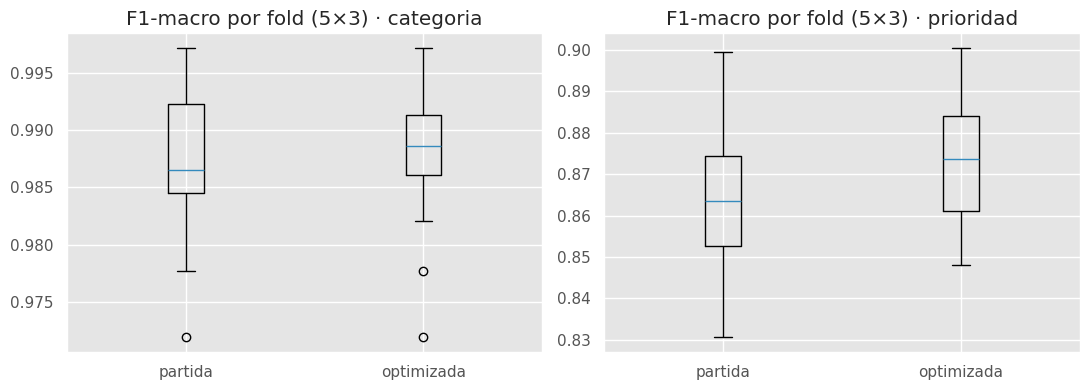

In [10]:
fig, ax = plt.subplots(1, len(OBJ), figsize=(11, 4))
for a_, o in zip(np.atleast_1d(ax), OBJ):
    r = antes_despues[o]
    a_.boxplot([r["antes"]["folds"], r["despues"]["folds"]], tick_labels=["partida", "optimizada"])
    a_.set_title(f"F1-macro por fold (5×3) · {o}")
guardar_fig("04_antes_despues")

## 5. Configuración final

Por objetivo se elige la optimizada **solo si** hay evidencia de mejora; si no, se mantiene la de partida (más simple y ya validada). El modelo final se entrena con los 1.300 textos de entrenamiento y validación y se guarda como `models/best_model.joblib`.

In [11]:
finales = {o: (mejores[o] if antes_despues[o]["hay_mejora"] else dict(cfg["svm"])) for o in OBJ}
guardar_json(finales, f"{MET}/mejores_params_svm.json")
modelos = {o: construir_svm(finales[o], SEMILLA).fit(dev["texto"], dev[o]) for o in OBJ}
final = ClasificadorTriaje(modelos, cfg["areas"], cfg["decision"]["umbral_confianza"], cfg["decision"]["terminos_influyentes"],
                           metadatos={"version": "v2_svm_final", "params": finales, "entrenado_con": "train+val (1.300)",
                                      "sklearn": sklearn.__version__})
final.guardar("models/best_model.joblib")
guardar_json({o: {"trials": len(estudios[o].trials), "mejor_cv": estudios[o].best_value, "base_cv": estudios[o].trials[0].value,
                  "mejores_params": estudios[o].best_params, "importancias": importancias[o],
                  "rango_trials": [min(valores[o]), max(valores[o])], "antes_despues": antes_despues[o],
                  "params_finales": finales[o]} for o in OBJ}, f"{MET}/04_optimizacion.json")
for o in OBJ:
    estudios[o].trials_dataframe().to_csv(f"{MET}/04_trials_{o}.csv", index=False)

00:07:55 | INFO | src.model | Modelo guardado en /content/drive/MyDrive/triajeia-isp/models/best_model.joblib
INFO:src.model:Modelo guardado en /content/drive/MyDrive/triajeia-isp/models/best_model.joblib


In [12]:
# Guarda el registro del entorno. En Colab, los resultados ya quedaron en Google Drive
# (MyDrive/triajeia-isp/results y models). Descargue además este notebook con sus salidas:
# Archivo → Descargar → .ipynb, y colóquelo en notebooks/ del repositorio.
guardar_json(entorno(), f"{MET}/entorno_{NB}.json")
print("Listo:", NB)

Listo: 04
